## Question 4

Overall answer: perhaps I did this wrong, but none of the residuals seem normal across all four model families... hence squared error loss might not be the best choice here.

Main choices and observations:
- 50-50 split for test / training data
- Distribution of residuals is right skewed with heavy tails
- There are a couple outliers in the data with very high ale that mess things up (can see them in the charts showing the distribution of residuals)

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/mcs_ds_edited_iter_shuffled.csv")

feature_cols = ["anchor_ratio", "trans_range", "node_density", "iterations"]
X = df[feature_cols]
y = df["ale"]

In [130]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
X_train.shape, X_test.shape

((53, 4), (54, 4))

### Helper functions

In [131]:
def plot_model(model, title, X_data, y_data, data_label):
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)

    for ax, col in zip(axes.flat, feature_cols):
        # 100 evenly spaced values across this feature's range
        grid = np.linspace(X_train[col].min(), X_train[col].max(), 100)

        # 100 copies of the "average" row, then vary only this one feature
        X_line = pd.DataFrame([X_train.mean()] * 100)
        X_line[col] = grid

        ax.scatter(X_data[col], y_data, s=30, color="#2a78d6", alpha=0.5, label=data_label)
        ax.plot(grid, model.predict(X_line), color="#eb6834", linewidth=2,
                label="model (others held at average)")
        ax.set_xlabel(col)
        ax.grid(alpha=0.3)

    axes[0, 0].set_ylabel("ale")
    axes[1, 0].set_ylabel("ale")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [132]:
def plot_residuals(y_true, y_pred, title, bins=20):
    residuals = y_true - y_pred
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

    # Left: predicted vs actual
    ax1.scatter(y_pred, y_true, s=30, color="#2a78d6", alpha=0.6)
    lims = [min(y_pred.min(), y_true.min()), max(y_pred.max(), y_true.max())]
    ax1.plot(lims, lims, color="#eb6834", linewidth=2, label="perfect prediction")
    ax1.set_xlabel("predicted ale")
    ax1.set_ylabel("actual ale")
    ax1.legend(frameon=False)
    ax1.grid(alpha=0.3)

    # Right: histogram of residuals
    ax2.hist(residuals, bins=bins, color="#2a78d6", edgecolor="white")
    ax2.axvline(0, color="#eb6834", linewidth=2)
    ax2.set_xlabel("residual (actual - predicted)")
    ax2.set_ylabel("count")
    ax2.grid(alpha=0.3)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [133]:
def plot_qq(residuals, title):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    stats.probplot(residuals, dist="norm", plot=ax)
    ax.get_lines()[0].set(color="#2a78d6", markersize=6, alpha=0.7)
    ax.get_lines()[1].set(color="#eb6834", linewidth=2)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    plt.show()

In [134]:
def normality_report(residuals, label):
    stat, p = stats.normaltest(residuals)
    print(label)
    print(f"  n:               {len(residuals)}")
    print(f"  skewness:        {stats.skew(residuals):.3f}")
    print(f"  excess kurtosis: {stats.kurtosis(residuals):.3f}")
    print(f"  normaltest stat: {stat:.3f}, p-value: {p:.3g}")

### Linear model

In [135]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.01,-0.04,-0. ,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['anchor_ratio','trans_range','node_density','iterations']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.857
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


anchor_ratio   -0.010767
trans_range    -0.036134
node_density   -0.004313
iterations     -0.006754
dtype: float64
intercept: 2.857327795046251


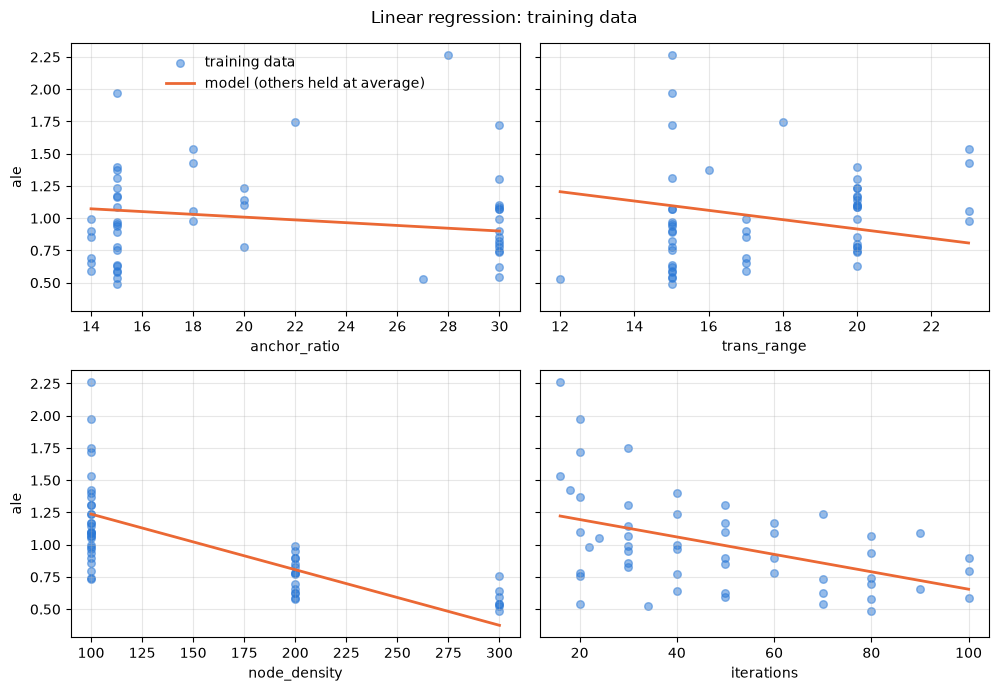

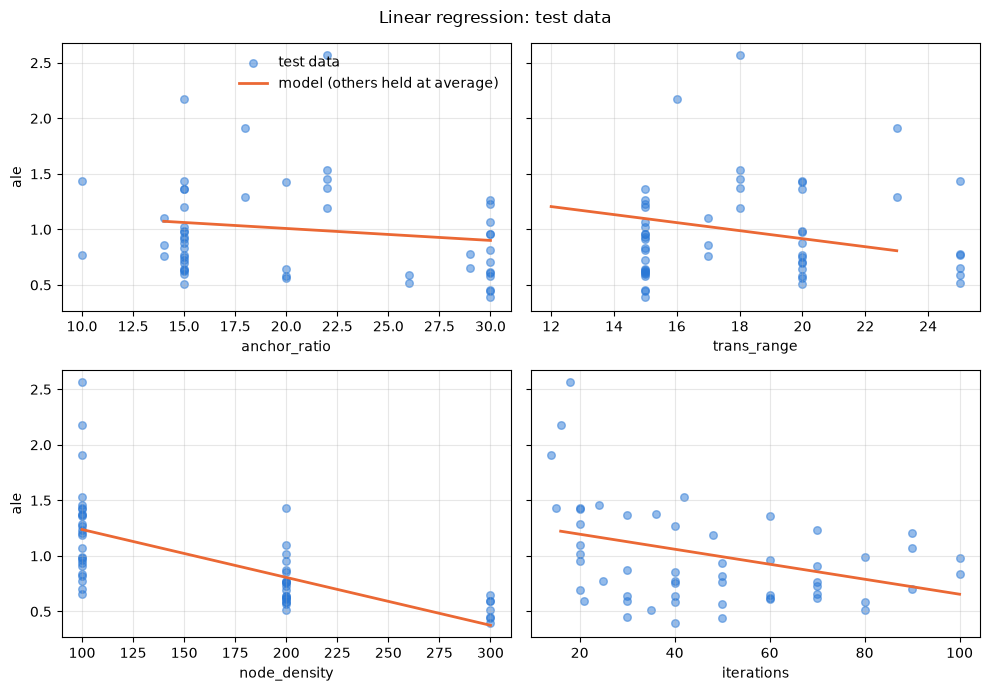

In [136]:
print(pd.Series(lin.coef_, index=feature_cols))
print("intercept:", lin.intercept_)

plot_model(lin, "Linear regression: training data", X_train, y_train, "training data")
plot_model(lin, "Linear regression: test data", X_test, y_test, "test data")

In [137]:
lin_pred = lin.predict(X_test)
lin_resid = y_test - lin_pred

print("train R^2:", lin.score(X_train, y_train))
print("test R^2: ", lin.score(X_test, y_test))
print("fraction of residuals < 0:", (lin_resid < 0).mean())
if (lin_resid < 0).mean() > 0.5:
    print("most of the residuals are negative")

lin_resid.describe()

train R^2: 0.6963290543225584
test R^2:  0.6201587182476018
fraction of residuals < 0: 0.5925925925925926
most of the residuals are negative


count    54.000000
mean      0.011467
std       0.271149
min      -0.450913
25%      -0.111186
50%      -0.030194
75%       0.080086
max       1.151206
Name: ale, dtype: float64

number of test points: 54


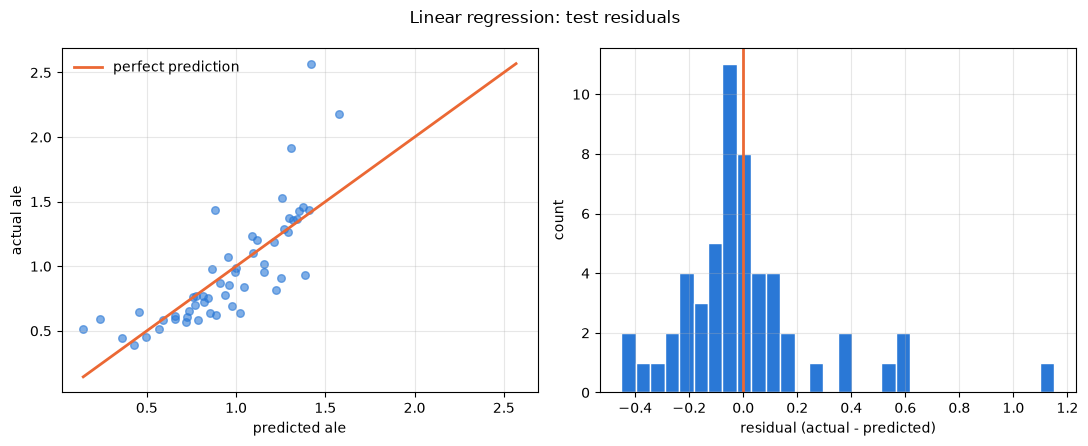

In [138]:
print("number of test points:", len(y_test))
plot_residuals(y_test, lin_pred, "Linear regression: test residuals", bins=30)

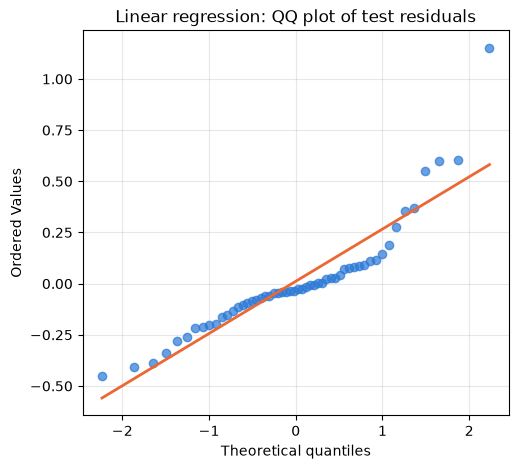

Linear regression: test residuals
  n:               54
  skewness:        1.702
  excess kurtosis: 4.808
  normaltest stat: 31.815, p-value: 1.23e-07


In [139]:
plot_qq(lin_resid, "Linear regression: QQ plot of test residuals")
normality_report(lin_resid, "Linear regression: test residuals")

### SVM (Support Vector Machine)

https://en.wikipedia.org/wiki/Support_vector_machine

In [140]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svr = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1.0, epsilon=0.1))
svr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['anchor_ratio','trans_range','node_density','iterations']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


number of support vectors: 30 out of 53


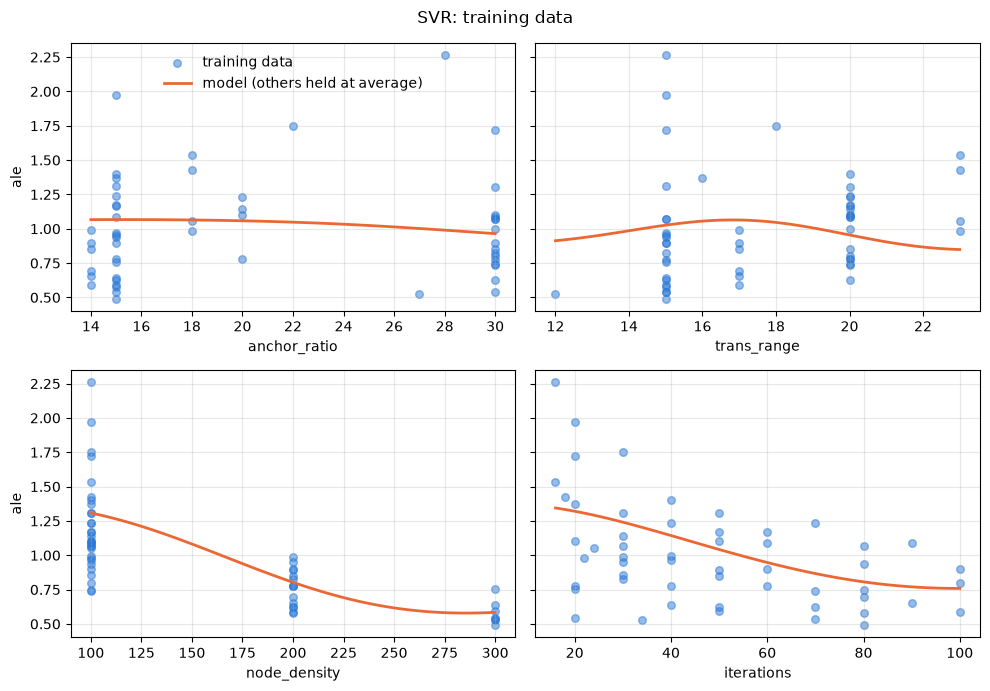

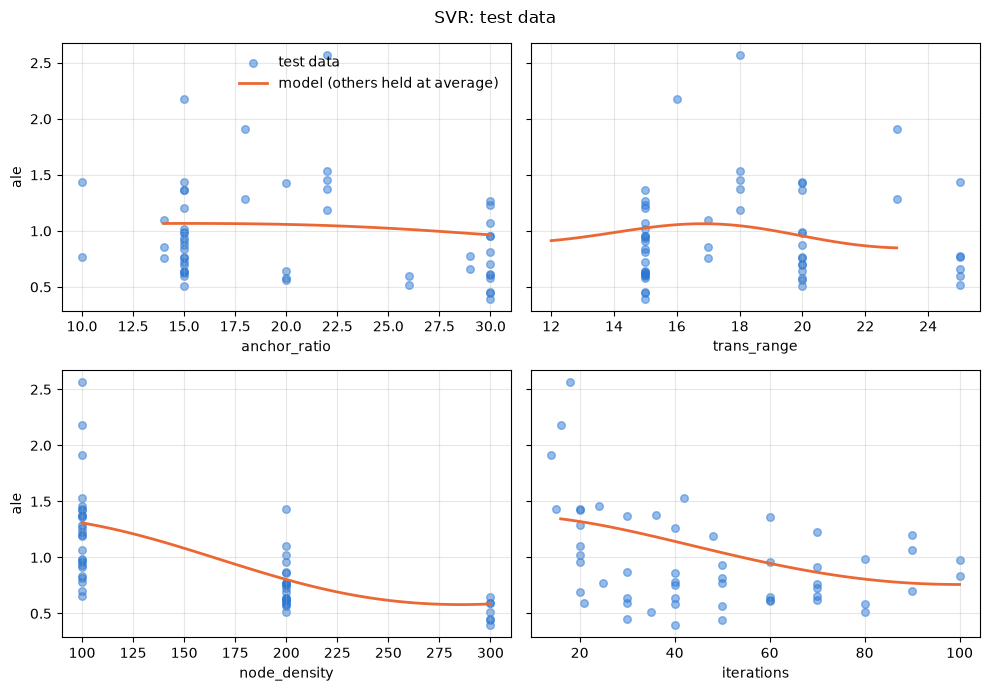

In [141]:
print("number of support vectors:", len(svr[-1].support_), "out of", len(X_train))
plot_model(svr, "SVR: training data", X_train, y_train, "training data")
plot_model(svr, "SVR: test data", X_test, y_test, "test data")

In [142]:
svr_pred = svr.predict(X_test)
svr_resid = y_test - svr_pred

print("train R^2:", svr.score(X_train, y_train))
print("test R^2: ", svr.score(X_test, y_test))
print("fraction of residuals < 0:", (svr_resid < 0).mean())
if (svr_resid < 0).mean() > 0.5:
    print("most of the residuals are negative")

svr_resid.describe()

train R^2: 0.7914644732471606
test R^2:  0.6563883420189034
fraction of residuals < 0: 0.6666666666666666
most of the residuals are negative


count    54.000000
mean     -0.010161
std       0.257925
min      -0.396098
25%      -0.140994
50%      -0.080170
75%       0.022085
max       1.013014
Name: ale, dtype: float64

number of test points: 54


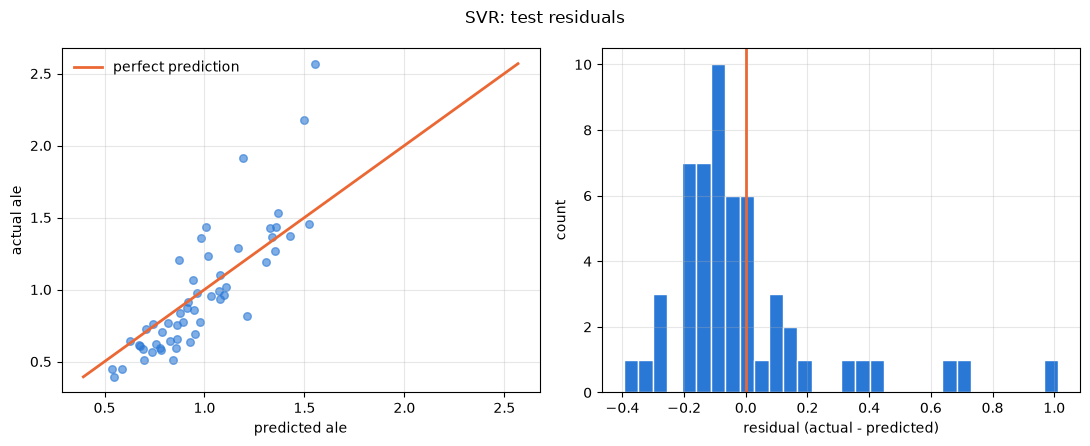

In [143]:
print("number of test points:", len(y_test))
plot_residuals(y_test, svr_pred, "SVR: test residuals", bins=30)

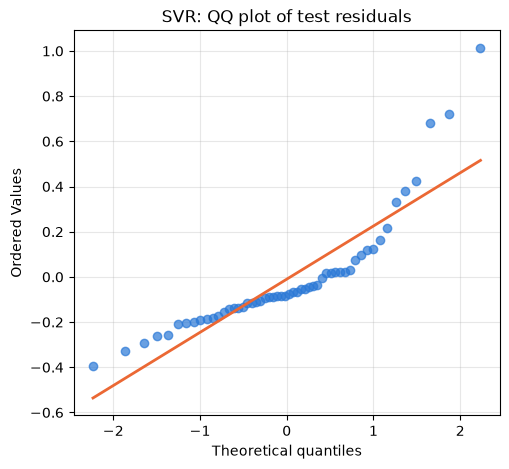

SVR: test residuals
  n:               54
  skewness:        1.986
  excess kurtosis: 4.572
  normaltest stat: 35.320, p-value: 2.14e-08


In [144]:
plot_qq(svr_resid, "SVR: QQ plot of test residuals")
normality_report(svr_resid, "SVR: test residuals")

### Decision tree

https://en.wikipedia.org/wiki/Decision_tree_model

In [145]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree = DecisionTreeRegressor(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

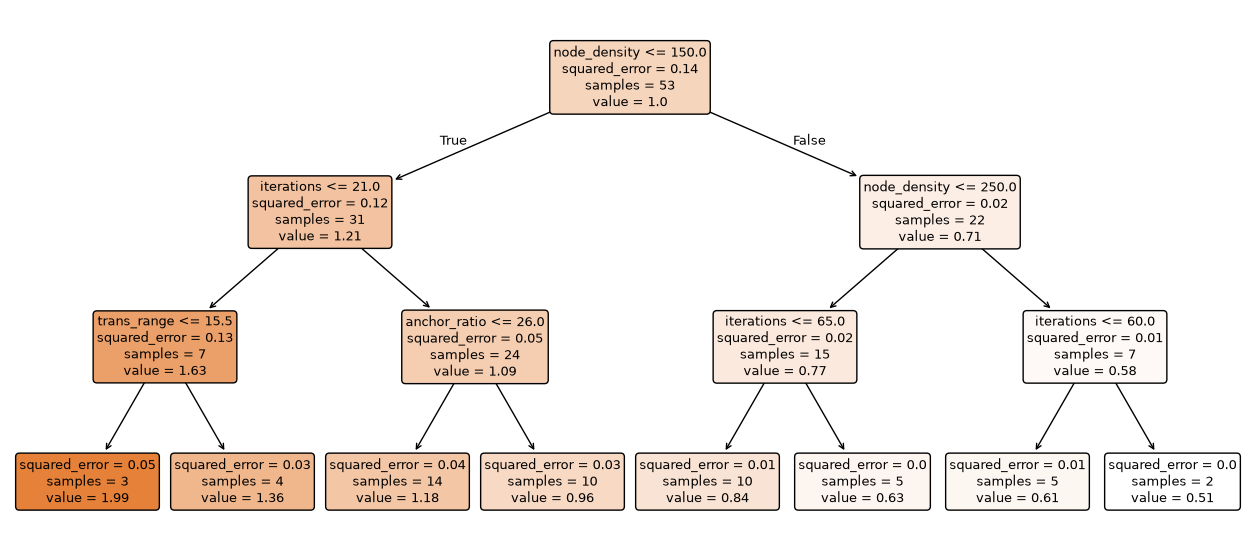

In [146]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, feature_names=feature_cols, filled=True, rounded=True,
          precision=2, fontsize=9, ax=ax)
plt.show()

number of leaves: 8


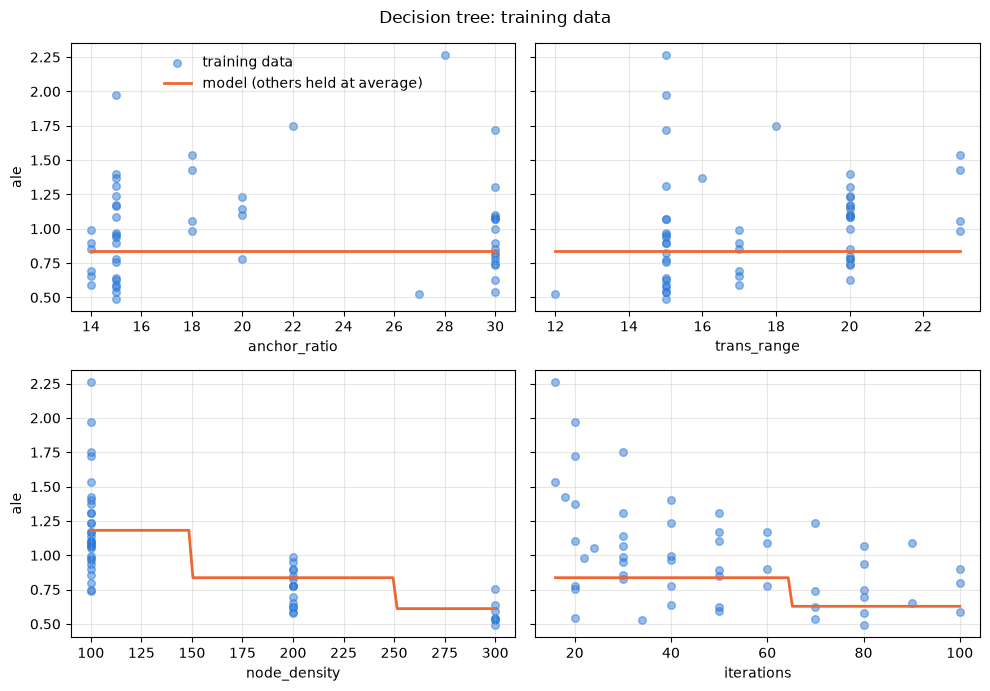

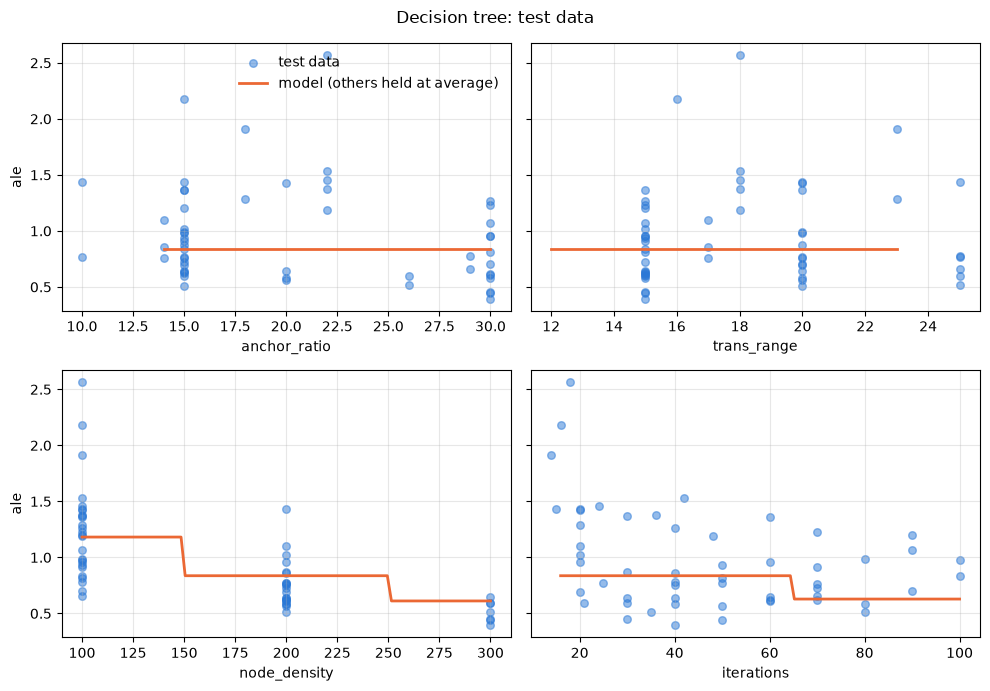

In [147]:
print("number of leaves:", tree.get_n_leaves())
plot_model(tree, "Decision tree: training data", X_train, y_train, "training data")
plot_model(tree, "Decision tree: test data", X_test, y_test, "test data")

In [148]:
tree_pred = tree.predict(X_test)
tree_resid = y_test - tree_pred

print("train R^2:", tree.score(X_train, y_train))
print("test R^2: ", tree.score(X_test, y_test))
print("distinct predictions:", len(np.unique(tree_pred)))
print("fraction of residuals < 0:", (tree_resid < 0).mean())
if (tree_resid < 0).mean() > 0.5:
    print("most of the residuals are negative")

tree_resid.describe()

train R^2: 0.8280909836152369
test R^2:  0.5660269704788126
distinct predictions: 6
fraction of residuals < 0: 0.5370370370370371
most of the residuals are negative


count    54.000000
mean      0.024815
std       0.289007
min      -0.346208
25%      -0.190760
50%      -0.016994
75%       0.129145
max       1.209395
Name: ale, dtype: float64

number of test points: 54


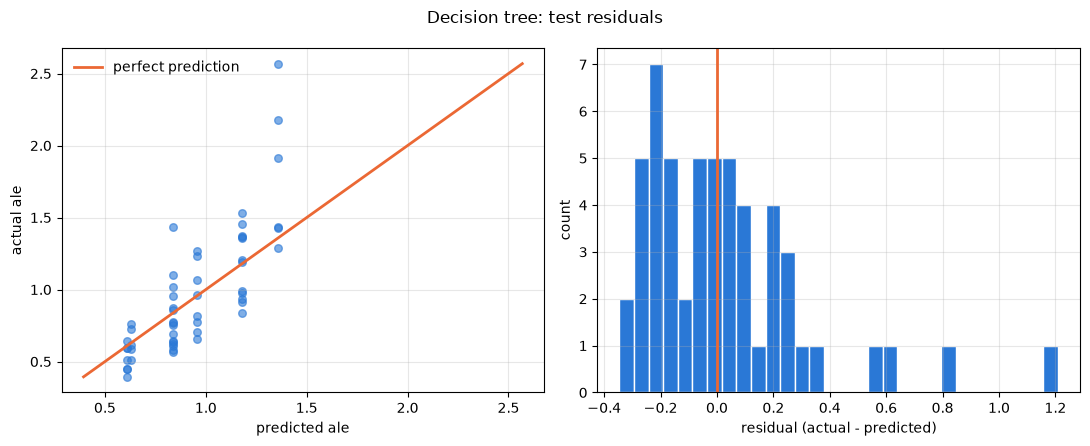

In [149]:
print("number of test points:", len(y_test))
plot_residuals(y_test, tree_pred, "Decision tree: test residuals", bins=30)

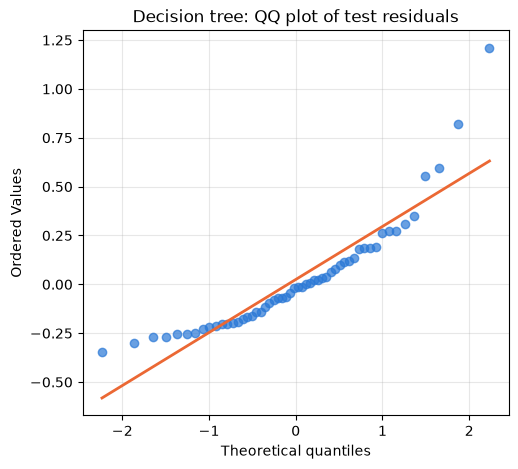

Decision tree: test residuals
  n:               54
  skewness:        1.808
  excess kurtosis: 4.370
  normaltest stat: 32.341, p-value: 9.49e-08


In [150]:
plot_qq(tree_resid, "Decision tree: QQ plot of test residuals")
normality_report(tree_resid, "Decision tree: test residuals")

### Neural network

In [151]:
from sklearn.neural_network import MLPRegressor

mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 64),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        alpha=0.0001,
        max_iter=2000,
        random_state=0,
    ),
)
mlp.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['anchor_ratio','trans_range','node_density','iterations']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


epochs run: 83
final training loss: 0.014039074780770456


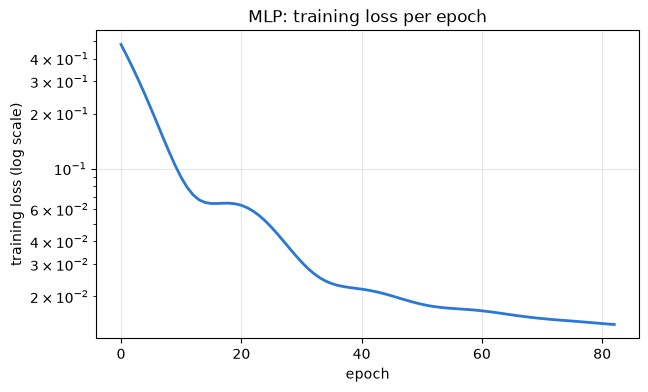

In [152]:
net = mlp[-1]
print("epochs run:", net.n_iter_)
print("final training loss:", net.loss_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(net.loss_curve_, color="#2a78d6", linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (log scale)")
ax.set_title("MLP: training loss per epoch")
ax.grid(alpha=0.3)
plt.show()

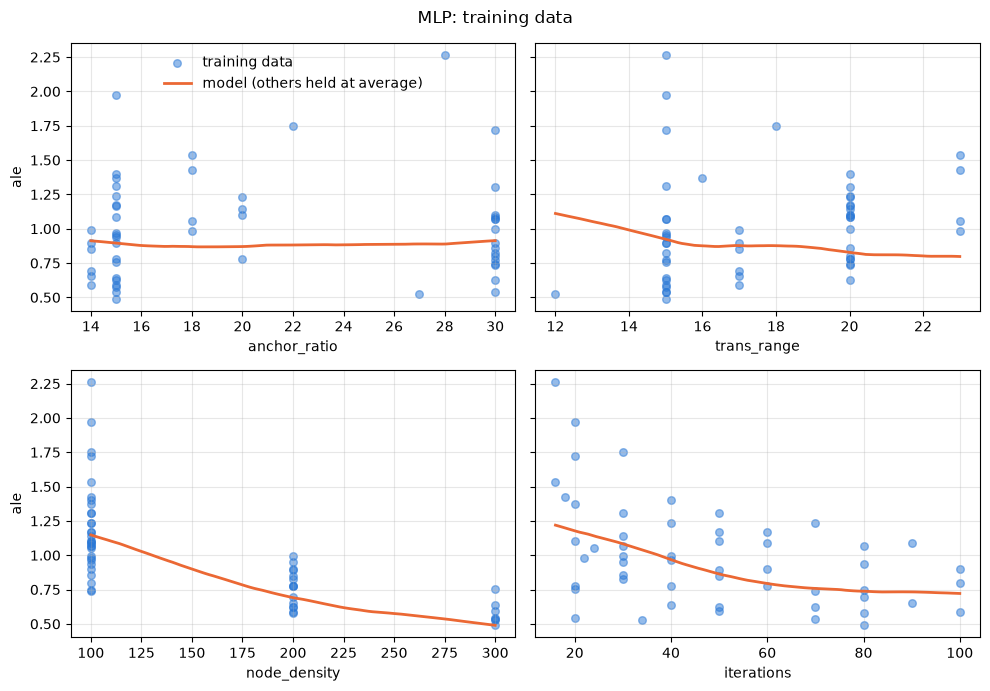

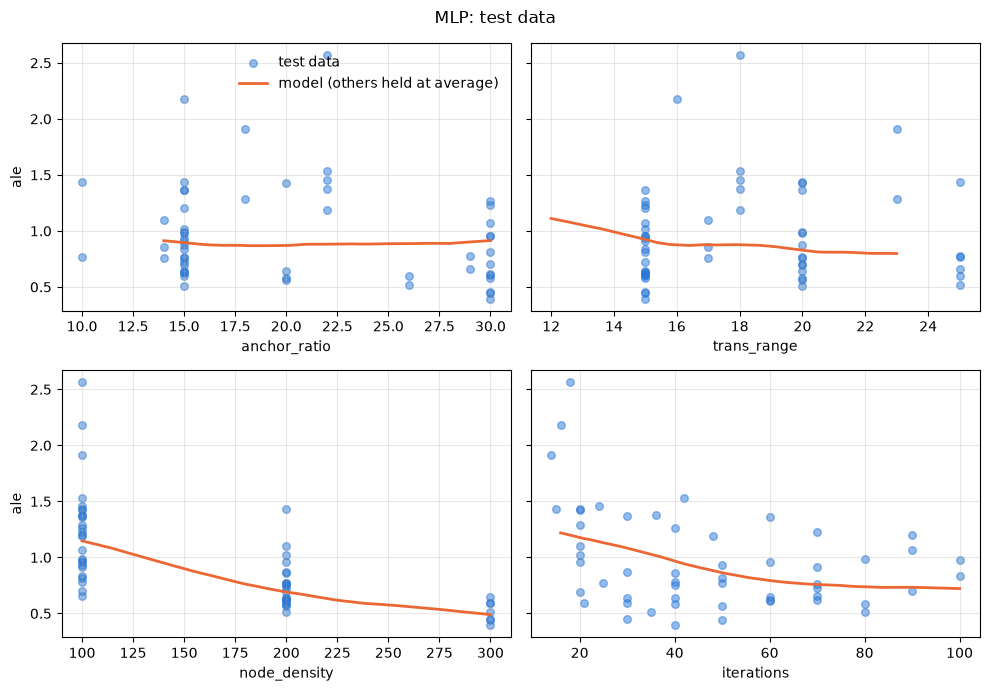

In [153]:
plot_model(mlp, "MLP: training data", X_train, y_train, "training data")
plot_model(mlp, "MLP: test data", X_test, y_test, "test data")

In [154]:
# testing stability

from sklearn.base import clone

for seed in range(5):
    m = clone(mlp).set_params(mlpregressor__random_state=seed)
    m.fit(X_train, y_train)
    print(f"seed {seed}: train R^2 = {m.score(X_train, y_train):.3f}, "
          f"test R^2 = {m.score(X_test, y_test):.3f}, epochs = {m[-1].n_iter_}")

seed 0: train R^2 = 0.800, test R^2 = 0.683, epochs = 83
seed 1: train R^2 = 0.749, test R^2 = 0.487, epochs = 102
seed 2: train R^2 = 0.781, test R^2 = 0.673, epochs = 92
seed 3: train R^2 = 0.837, test R^2 = 0.711, epochs = 84
seed 4: train R^2 = 0.797, test R^2 = 0.608, epochs = 93


In [155]:
mlp_pred = mlp.predict(X_test)
mlp_resid = y_test - mlp_pred

print("train R^2:", mlp.score(X_train, y_train))
print("test R^2: ", mlp.score(X_test, y_test))
print("fraction of residuals < 0:", (mlp_resid < 0).mean())
if (mlp_resid < 0).mean() > 0.5:
    print("most of the residuals are negative")

mlp_resid.describe()

train R^2: 0.7998769394747106
test R^2:  0.6825623660138933
fraction of residuals < 0: 0.6111111111111112
most of the residuals are negative


count    54.000000
mean     -0.009275
std       0.247926
min      -0.517563
25%      -0.126148
50%      -0.028751
75%       0.063666
max       1.077528
Name: ale, dtype: float64

number of test points: 54


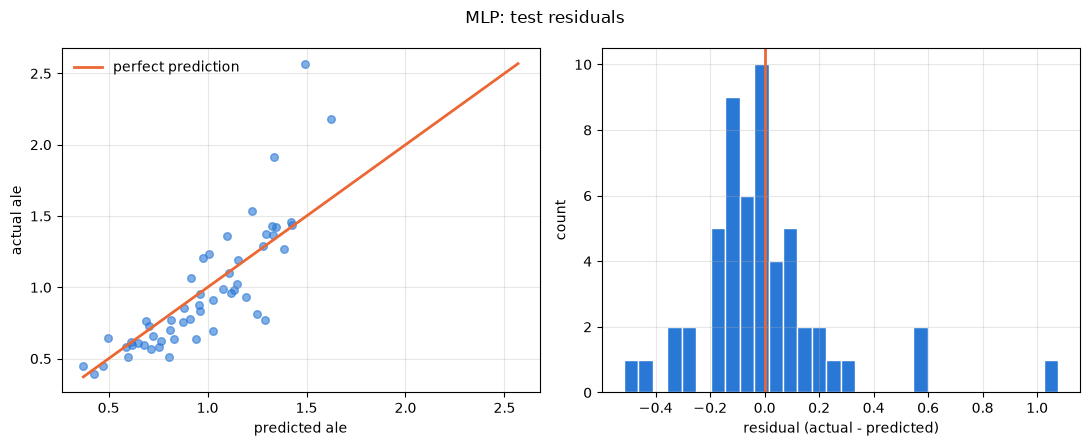

In [156]:
print("number of test points:", len(y_test))
plot_residuals(y_test, mlp_pred, "MLP: test residuals", bins=30)

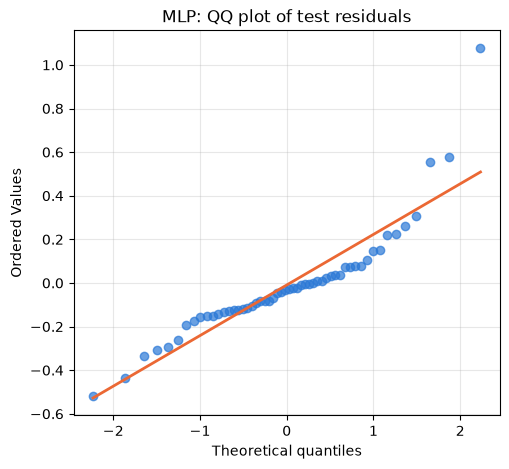

MLP: test residuals
  n:               54
  skewness:        1.764
  excess kurtosis: 6.002
  normaltest stat: 35.159, p-value: 2.32e-08


In [157]:
plot_qq(mlp_resid, "MLP: QQ plot of test residuals")
normality_report(mlp_resid, "MLP: test residuals")